<div style="background:linear-gradient(125deg,#19152f 0%,#3a2861 55%,#664bb0 100%);padding:34px 32px;border-radius:20px;color:#fff;box-shadow:0 12px 28px #30224b20">
<div style="font-size:12px;letter-spacing:2.4px;color:#d7cafa;font-weight:700">DLS Diffusion Week 2026</div>
</div>
<h1 style="font-size:36px;line-height:1.18;color:#fff;margin:12px 0">Персонализация Stable Diffusion</h1>
<p style="color:#64748b; font-size:14px;">Автор: <a href="https://t.me/OnlyGensAI" target="_blank" style="color:#9333EA; text-decoration:none; font-weight:600;">@OnlyGensAI ↗</a></p>
</div>

## Дообучение SD c использованием библиотеки [d🧨ffusers](https://github.com/huggingface/diffusers)
На **одном наборе из 3 изображений** научим Stable Diffusion генерировать чебурашку, которого она раньше никогда не видела/видела очень мало. Протестируем 3 метода дообучения, у всех из них **общий датасет, общая диффузионная функция потерь и общий цикл оптимизации**, но различается набор обучаемых весов.

| Метод | Что меняем | Что остаётся замороженным |
|:---|:---|:---|
| **Textual Inversion** | Вектор эмбеддинга одного нового токена | U-Net, VAE, остальной text encoder |
| **DreamBooth*** | Все веса U-Net + text_encoder (optional) | VAE |
| **LoRA, rank 4** | Низкоранговые матрицы в attention-проекциях U-Net и text_encoder (optional)| Исходные веса U-Net, text_encoder, VAE |
| **IP-Adapter** | Ничего: используем предобученный адаптер | Вся генеративная модель |
| **ControlNet / Canny** | Ничего: используем предобученную сеть контроля | Вся генеративная модель |

> ***Замечание:** В демонстрационном DreamBooth не используются prior preservation и class images — это отличие от полной методики оригинальной статьи.

![Dreambooth Example](https://raw.githubusercontent.com/V-Soboleva/PML_practice/main/cheburashka/preview.png)

## 00 · Подготовка среды

Устанавливаем библиотеки.

Основная модель — **Stable Diffusion 2.0 (768×768)**: все три метода обучения в родном разрешении влезают в T4 (пик памяти: TI ~8 GiB, LoRA ~7 GiB, DreamBooth ~11 GiB). Для IP-Adapter и ControlNet (разделы 08–09) используем SD 1.5: для неё есть официальные адаптеры и множество готовых LoRA.

In [ ]:
%pip uninstall -y torchao
%pip -q install -U "diffusers>=0.35,<0.41" "transformers>=4.46,<5" "accelerate>=1.0,<2" "peft>=0.13,<1" "huggingface_hub>=0.27,<2" "safetensors>=0.5" "ftfy" "opencv-python-headless" "matplotlib" "bitsandbytes>=0.45"

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [ ]:
import gc
import random
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import requests
import torch
from PIL import Image, ImageOps
from IPython.display import display
from matplotlib import pyplot as plt
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from accelerate import Accelerator
from accelerate.utils import set_seed
from diffusers import (
    AutoencoderKL, DDPMScheduler, StableDiffusionPipeline,
    UNet2DConditionModel, ControlNetModel, StableDiffusionControlNetPipeline,
)
from diffusers.utils import load_image, convert_state_dict_to_diffusers
from huggingface_hub import hf_hub_download
from peft import LoraConfig, get_peft_model_state_dict
from safetensors.torch import save_file
from tqdm.auto import tqdm
from transformers import CLIPTextModel, CLIPTokenizer

assert torch.cuda.is_available(), "Включите GPU в Colab: Runtime → Change runtime type → T4 GPU"
DEVICE = "cuda"

# SD 2.0 (768×768, v-prediction): зеркало stabilityai/stable-diffusion-2, которое удалено с HF.
MODEL_ID = "sd2-community/stable-diffusion-2"
RESOLUTION = 768
# IP-Adapter, ControlNet и стилевая LoRA из разделов 08–09 обучены под SD 1.5 и с SD 2 несовместимы.
SD15_MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"

TRAIN_SEED = 3434554
GEN_SEED, GEN_STEPS, GEN_GUIDANCE, GEN_NUM_IMAGES = 5, 25, 9.0, 2

ROOT = Path("/content/sd-personalization") if Path("/content").exists() else Path("./sd-personalization")
ROOT.mkdir(parents=True, exist_ok=True)
TI_DIR = ROOT / "textual_inversion"
DB_DIR = ROOT / "dreambooth"
DB_TE_DIR = ROOT / "cheburashka-db-te"   # готовый чекпойнт DreamBooth + CLIP
LORA_DIR = ROOT / "lora"

random.seed(TRAIN_SEED); np.random.seed(TRAIN_SEED); torch.manual_seed(TRAIN_SEED)
print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)
import diffusers, transformers, peft
print("Diffusers:", diffusers.__version__, "Transformers:", transformers.__version__, "PEFT:", peft.__version__)

Multiple distributions found for package optimum. Picked distribution: optimum


GPU: NVIDIA H100 80GB HBM3
PyTorch: 2.7.0+cu128
Diffusers: 0.37.0.dev0 Transformers: 4.57.1 PEFT: 0.18.1


## 01 · Один датасет для всех методов

Используем три изображения игрушечного персонажа из исходного ноутбука. **Объект и изображения одинаковы во всех экспериментах**, поэтому можно сравнить влияние способа адаптации.

- Для **Textual Inversion** вводим специальный токен `<cheburashka>` и обучаем только его embedding.
- Для **DreamBooth и LoRA** используем редкий идентификатор `<cheburashka>` внутри описания класса: `<cheburashka> plushie`.
- Класс `plushie` помогает модели понять, на чем именно ей фокусироваться во время обучения.


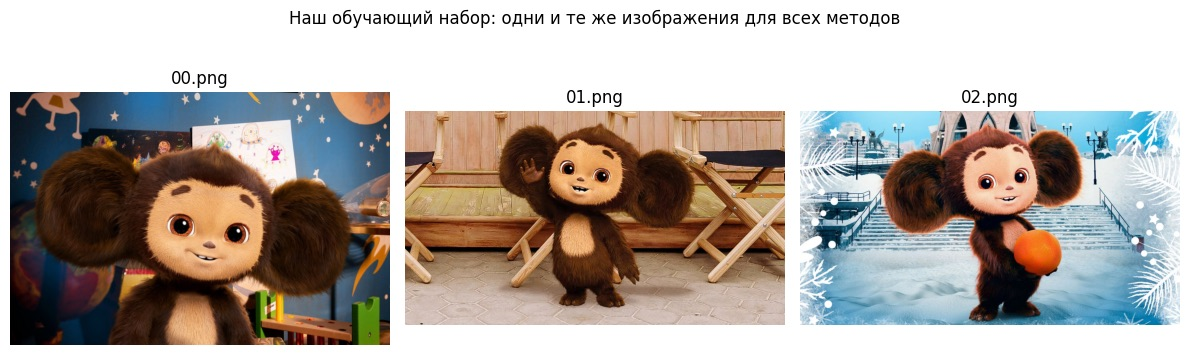

In [ ]:
IMAGE_URLS = [
    f"https://raw.githubusercontent.com/V-Soboleva/PML_practice/main/cheburashka/{i}.png"
    for i in (1, 2, 3)
]
DATA_DIR = ROOT / "images"
DATA_DIR.mkdir(parents=True, exist_ok=True)

for i, url in enumerate(IMAGE_URLS):
    path = DATA_DIR / f"{i:02d}.png"
    if not path.exists():
        response = requests.get(url, timeout=30)
        response.raise_for_status()  # Не скрываем ошибки загрузки.
        with Image.open(__import__("io").BytesIO(response.content)) as image:
            image.convert("RGB").save(path)

image_paths = sorted(DATA_DIR.glob("*.png"))
fig, axes = plt.subplots(1, len(image_paths), figsize=(12, 4))
for ax, path in zip(np.atleast_1d(axes), image_paths):
    ax.imshow(Image.open(path)); ax.axis("off"); ax.set_title(path.name)
plt.suptitle("Наш обучающий набор: одни и те же изображения для всех методов")
plt.tight_layout(); plt.show()

## 02 · Общий каркас обучения

Все методы минимизируют **одну и ту же диффузионную MSE-потерю**:

$$z_0 = E(x),\quad z_t=\sqrt{\bar\alpha_t}z_0+\sqrt{1-\bar\alpha_t}\epsilon,\quad \mathcal{L}=\left\|\epsilon-\epsilon_\theta(z_t,t,c)\right\|_2^2.$$

Здесь `E` — замороженный VAE encoder; `c` — текстовое условие. **Мы меняем не loss, а обучаемые параметры.**

**Важно: что именно предсказывает модель.** SD 1.x и SD 2.x-base обучены предсказывать шум $\epsilon$, а наша SD 2 (768) — *скорость* $v=\sqrt{\bar\alpha_t}\,\epsilon-\sqrt{1-\bar\alpha_t}\,z_0$ (`prediction_type="v_prediction"` в конфиге scheduler). Тогда в loss вместо $\epsilon$ стоит $v$.

**Переключатели text encoder.** Для DreamBooth `True` размораживает весь CLIP text encoder, а для LoRA добавляет в него отдельные низкоранговые адаптеры. Оба эксперимента используют тот же общий training loop. По умолчанию оба выключены: включённый CLIP увеличивает расход памяти (полный DreamBooth + CLIP — ~14.3 GiB из 15 GiB на T4).


In [ ]:
@dataclass
class TrainConfig:
    method: str
    prompt: str
    lr: float
    steps: int                      # шаги оптимизатора, каждый = grad_accum микробатчей
    batch_size: int = 2
    grad_accum: int = 2
    resolution: int = RESOLUTION
    max_grad_norm: float = 1.0
    seed: int = TRAIN_SEED
    use_8bit_adam: bool = True      # bitsandbytes AdamW8bit: состояния оптимизатора в 4 раза меньше

# Два независимых эксперимента: можно переключать обучение CLIP без изменения остального кода.
# DreamBooth + CLIP занимает ~14.3 GiB — на T4 впритык, готовый чекпойнт есть в разделе 04.1.
DREAMBOOTH_TRAIN_TEXT_ENCODER = False  # True: полное обучение CLIP вместе с U-Net
LORA_TRAIN_TEXT_ENCODER = False        # True: LoRA-матрицы ещё и в CLIP
LORA_RANK = 4

prompt = "<cheburashka> plushie"
CONFIGS = {
    "ti": TrainConfig("ti", prompt, lr=5e-4, steps=1000),
    "dreambooth": TrainConfig("dreambooth", prompt, lr=5e-6, steps=101),
    "lora": TrainConfig("lora", prompt, lr=1e-4, steps=400),
}

class ConceptDataset(Dataset):
    """Общий датасет: картинка + токенизированный текст для всех трёх запусков."""
    def __init__(self, paths, tokenizer, prompt, resolution=RESOLUTION):
        self.paths = paths
        self.prompt_ids = tokenizer(
            prompt, padding="max_length", max_length=tokenizer.model_max_length,
            truncation=True, return_tensors="pt"
        ).input_ids[0]
        self.transform = transforms.Compose([
            transforms.Resize(resolution, interpolation=transforms.InterpolationMode.BILINEAR),
            transforms.CenterCrop(resolution),
            transforms.ToTensor(),
            transforms.Normalize([0.5], [0.5]),
        ])

    def __len__(self): return len(self.paths)

    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image:
            pixels = self.transform(image.convert("RGB"))
        return {"pixel_values": pixels, "input_ids": self.prompt_ids.clone()}


def load_components():
    """Одинаковая начальная модель для каждого эксперимента."""
    tokenizer = CLIPTokenizer.from_pretrained(MODEL_ID, subfolder="tokenizer")
    text_encoder = CLIPTextModel.from_pretrained(MODEL_ID, subfolder="text_encoder")
    vae = AutoencoderKL.from_pretrained(MODEL_ID, subfolder="vae")
    unet = UNet2DConditionModel.from_pretrained(MODEL_ID, subfolder="unet")
    scheduler = DDPMScheduler.from_pretrained(MODEL_ID, subfolder="scheduler")
    return tokenizer, text_encoder, vae, unet, scheduler


def count_parameters(module):
    total = sum(p.numel() for p in module.parameters())
    trainable = sum(p.numel() for p in module.parameters() if p.requires_grad)
    print(f"Обучаемых параметров: {trainable:,} / {total:,} ({100 * trainable / total:.4f}%)")


def clear_gpu(*objects, verbose=True):
    """Освобождаем GPU между независимыми экспериментами."""
    for obj in objects:
        if obj is not None:
            try: obj.to("cpu")
            except (AttributeError, TypeError, RuntimeError): pass
    del objects
    gc.collect()
    torch.cuda.empty_cache()
    if verbose:
        print(f"Занято на GPU после очистки: {torch.cuda.memory_allocated() / 2**30:.2f} GiB")

### Центральная функция — одна для всех методов

Для каждого запуска передаём **U-Net, text encoder и оптимизируемые параметры**; функция сама определяет, каким компонентам нужны градиенты. Ничего не дублируем: датасет, зашумление, MSE, оптимизатор и цикл обновлений общие для TI, DreamBooth и PEFT-LoRA.

- **Textual Inversion** — обучается только embedding нового токена.
- **DreamBooth** — обучается U-Net и, по переключателю, весь CLIP text encoder.
- **LoRA** — обучаются LoRA-матрицы U-Net и, по переключателю, LoRA-матрицы CLIP.


In [ ]:
def train_one_method(cfg, tokenizer, text_encoder, vae, unet, noise_scheduler,
                     trainable_parameters, ti_token_id=None):
    """Общий цикл: меняются только флаги requires_grad и состав trainable_parameters."""
    set_seed(cfg.seed)
    accelerator = Accelerator(mixed_precision="fp16", gradient_accumulation_steps=cfg.grad_accum)
    dataset = ConceptDataset(image_paths, tokenizer, cfg.prompt, cfg.resolution)
    loader = DataLoader(dataset, batch_size=cfg.batch_size, shuffle=True,
                        drop_last=False, num_workers=0)

    trainable_parameters = list(trainable_parameters)
    assert trainable_parameters and all(p.requires_grad for p in trainable_parameters)
    # Нулевой weight decay особенно важен для Textual Inversion.
    if cfg.use_8bit_adam:
        import bitsandbytes as bnb
        optimizer = bnb.optim.AdamW8bit(trainable_parameters, lr=cfg.lr, weight_decay=0.0)
    else:
        optimizer = torch.optim.AdamW(trainable_parameters, lr=cfg.lr, weight_decay=0.0)

    # Accelerate оборачивает обе модели, если обе обучаются: общая синхронизация градиентов.
    # Даже при заморозке второго компонента мы передаём его в prepare для единообразия.
    unet, text_encoder, optimizer, loader = accelerator.prepare(
        unet, text_encoder, optimizer, loader
    )
    frozen_dtype = torch.float16
    vae.requires_grad_(False).to(accelerator.device, dtype=frozen_dtype).eval()
    if not any(p.requires_grad for p in unet.parameters()):
        unet.to(accelerator.device, dtype=frozen_dtype).eval()
    else:
        unet.train()
    if not any(p.requires_grad for p in text_encoder.parameters()):
        text_encoder.to(accelerator.device, dtype=frozen_dtype).eval()
    else:
        text_encoder.train()

    # В TI оптимизируется только одна строка embedding-матрицы.
    # Это значит что после каждого шага обучения остальные эмбеддинги надо вернуть к их оригинальным значениям
    original_embeddings = None
    if cfg.method == "ti":
        original_embeddings = accelerator.unwrap_model(text_encoder).get_input_embeddings().weight.detach().clone()

    torch.cuda.reset_peak_memory_stats()

    # cfg.steps — число шагов оптимизатора (как max_train_steps в diffusers),
    # каждый из них накапливает градиенты по grad_accum микробатчам.
    history, accum_losses = [], []
    iterator = iter(loader)
    progress = tqdm(total=cfg.steps, desc=cfg.method)
    global_step = 0
    while global_step < cfg.steps:
        try:
            batch = next(iterator)
        except StopIteration:
            iterator = iter(loader)
            batch = next(iterator)

        with accelerator.accumulate(unet, text_encoder):
            with torch.no_grad():
                latents = vae.encode(batch["pixel_values"].to(
                    accelerator.device, dtype=frozen_dtype
                )).latent_dist.sample() * vae.config.scaling_factor
                noise = torch.randn_like(latents)
                timesteps = torch.randint(
                    0, noise_scheduler.config.num_train_timesteps,
                    (latents.shape[0],), device=latents.device
                ).long()
                noisy_latents = noise_scheduler.add_noise(latents, noise, timesteps)
                # SD 1.x и SD 2.x-base предсказывают шум (epsilon), SD 2.x (768) — скорость v.
                if noise_scheduler.config.prediction_type == "v_prediction":
                    target = noise_scheduler.get_velocity(latents, noise, timesteps)
                else:
                    target = noise

            # no_grad только когда CLIP полностью заморожен; для CLIP-LoRA
            # и DreamBooth + CLIP градиент должен пройти через text encoder.
            with accelerator.autocast():
                if any(p.requires_grad for p in text_encoder.parameters()):
                    hidden_states = text_encoder(batch["input_ids"])[0]
                else:
                    with torch.no_grad():
                        hidden_states = text_encoder(batch["input_ids"])[0]
                prediction = unet(noisy_latents, timesteps, hidden_states).sample
                loss = torch.nn.functional.mse_loss(prediction.float(), target.float())
            accelerator.backward(loss)

            # Маскируем градиент нецелевых токенов ДО шага оптимизатора.
            if cfg.method == "ti" and accelerator.sync_gradients:
                weight = accelerator.unwrap_model(text_encoder).get_input_embeddings().weight
                if weight.grad is not None:
                    weight.grad[:ti_token_id] = 0
                    weight.grad[ti_token_id + 1:] = 0

            if accelerator.sync_gradients:
                accelerator.clip_grad_norm_(trainable_parameters, cfg.max_grad_norm)
            optimizer.step()
            optimizer.zero_grad(set_to_none=True)

            if cfg.method == "ti" and accelerator.sync_gradients:
                with torch.no_grad():
                    weight = accelerator.unwrap_model(text_encoder).get_input_embeddings().weight
                    learned_row = weight[ti_token_id].detach().clone()
                    weight.copy_(original_embeddings)
                    weight[ti_token_id] = learned_row

        accum_losses.append(float(loss.detach().cpu()))
        if accelerator.sync_gradients:
            history.append(float(np.mean(accum_losses)))
            accum_losses = []
            global_step += 1
            progress.update(1)
            progress.set_postfix(loss=f"{history[-1]:.3f}")
    progress.close()
    print(f"Пик памяти GPU: {torch.cuda.max_memory_reserved() / 2**30:.1f} GiB")

    # keep_fp32_wrapper=False: иначе выход U-Net останется fp32 и сломает fp16-инференс.
    return (accelerator.unwrap_model(unet, keep_fp32_wrapper=False),
            accelerator.unwrap_model(text_encoder, keep_fp32_wrapper=False), history)


def show_loss(history, title):
    plt.figure(figsize=(8, 2.6))
    plt.plot(history, linewidth=1.4)
    plt.title(title); plt.xlabel("Шаг оптимизатора"); plt.ylabel("MSE")
    plt.grid(alpha=0.2); plt.show()


In [ ]:
EVAL_PROMPTS = [
    "{}",
    "{} with the Eiffel Tower in the background",
    "{} on the beach",
    "a watercolor painting of {}",
]


def method_token(method):
    """Базовая модель не знает токена <cheburashka>, поэтому для неё пишем обычное слово."""
    return "cheburashka" if method == "base" else "<cheburashka>"


def load_pipe(method="base"):
    """Свежая fp16-pipeline: базовая SD2 + веса выбранного метода."""
    pipe = StableDiffusionPipeline.from_pretrained(
        MODEL_ID, torch_dtype=torch.float16, safety_checker=None, requires_safety_checker=False,
    )
    if method == "ti":
        pipe.load_textual_inversion(str(TI_DIR / "learned_embeds.safetensors"))
    elif method == "dreambooth":
        pipe.unet = UNet2DConditionModel.from_pretrained(DB_DIR / "unet", torch_dtype=torch.float16)
        if (DB_DIR / "text_encoder").exists():
            pipe.text_encoder = CLIPTextModel.from_pretrained(DB_DIR / "text_encoder", torch_dtype=torch.float16)
    elif method == "dreambooth_te":
        pipe.unet.load_state_dict(torch.load(DB_TE_DIR / "checkpoint-100" / "unet.bin", map_location="cpu"))
        pipe.text_encoder.load_state_dict(torch.load(DB_TE_DIR / "checkpoint-100" / "te.bin", map_location="cpu"))
    elif method == "lora":
        pipe.load_lora_weights(str(LORA_DIR), weight_name="pytorch_lora_weights.safetensors")
    elif method != "base":
        raise ValueError(f"Неизвестный метод: {method}")
    pipe.set_progress_bar_config(disable=True)
    return pipe.to(DEVICE)


@torch.inference_mode()
def generate(pipe, prompt, seed=GEN_SEED, num_images=GEN_NUM_IMAGES):
    # CPU-генератор: тот же сид даёт тот же шум на любой GPU.
    return pipe(
        prompt, height=RESOLUTION, width=RESOLUTION,
        num_inference_steps=GEN_STEPS, guidance_scale=GEN_GUIDANCE,
        num_images_per_prompt=num_images,
        generator=torch.Generator("cpu").manual_seed(seed),
    ).images


def show_method(method, title):
    """Сетка EVAL_PROMPTS × GEN_NUM_IMAGES для одного метода."""
    pipe = load_pipe(method)
    fig, axes = plt.subplots(len(EVAL_PROMPTS), GEN_NUM_IMAGES, squeeze=False,
                             figsize=(4 * GEN_NUM_IMAGES, 4.2 * len(EVAL_PROMPTS)))
    for row, template in zip(axes, EVAL_PROMPTS):
        prompt = template.format(method_token(method))
        for ax, image in zip(row, generate(pipe, prompt)):
            ax.imshow(image); ax.axis("off")
        row[0].set_title(prompt, loc="left", fontsize=10)
    fig.suptitle(title, fontsize=14)
    plt.tight_layout(); plt.show()
    del pipe
    clear_gpu(verbose=False)

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

2026-11-09 17:34:59.707021299 [W:onnxruntime:Default, device_discovery.cc:283 GetGpuDevices] Failed to detect devices under "/sys/class/drm/card0": device_discovery.cc:93 ReadFileContents Failed to open file: "/sys/class/drm/card0/device/vendor"


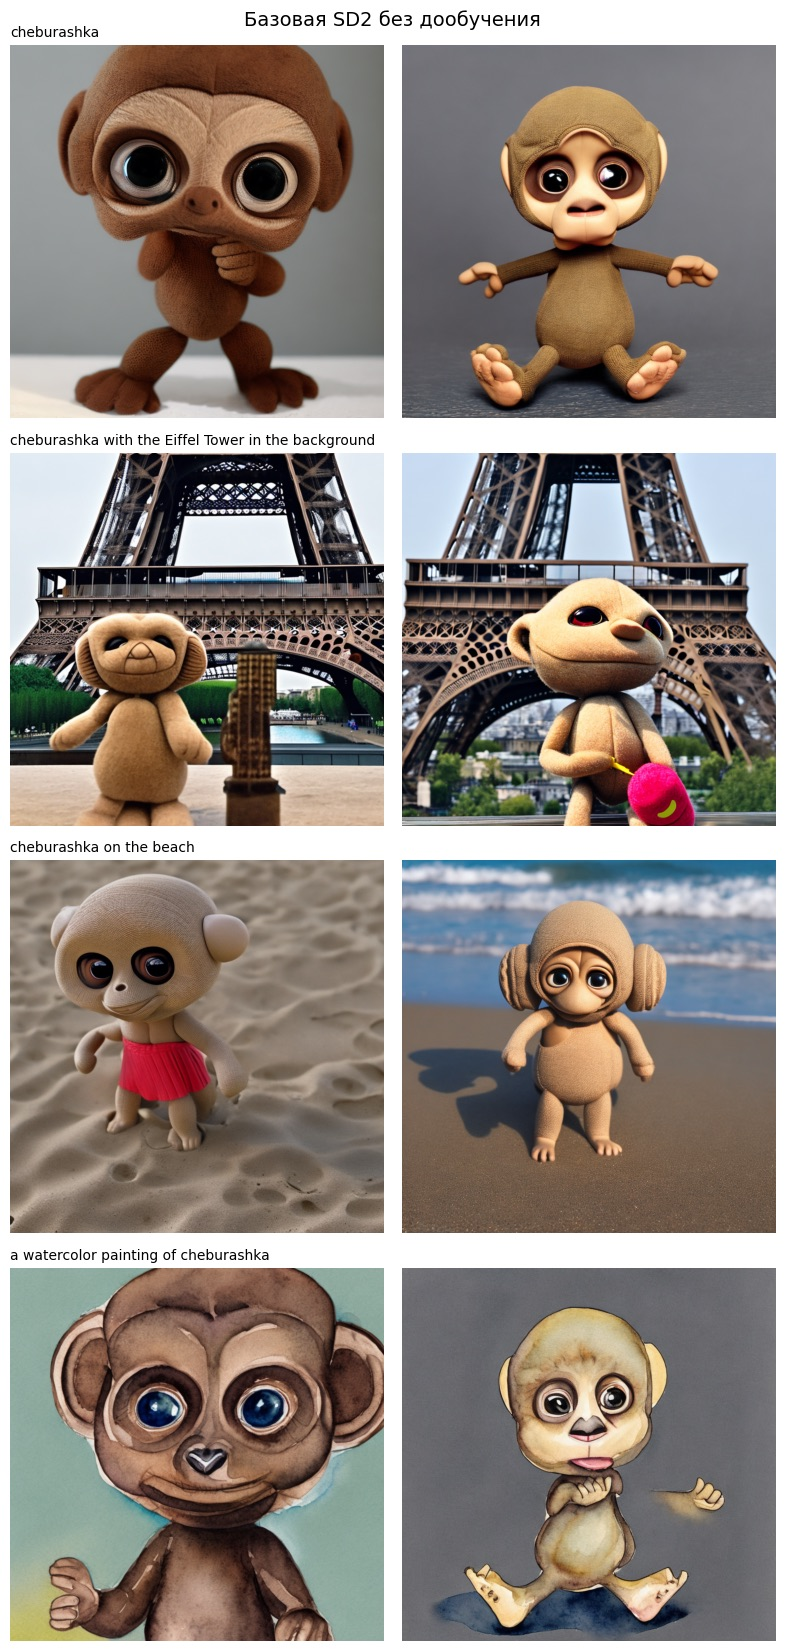

In [ ]:
# Точка отсчёта: базовая SD2 Чебурашку не знает и рисует «какую-то обезьянку».
show_method("base", "Базовая SD2 без дообучения")

### Бу, испугался? не бойся, я друг... Ну, а что вы хотели, это SD-2... ¯\_(ツ)_/¯


## 03 · Textual Inversion

📖 [**Статья · Gal et al., 2022 — An Image is Worth One Word: Personalizing Text-to-Image Generation using Textual Inversion**](https://arxiv.org/abs/2208.01618)

<div style="margin:22px 0 18px;text-align:center">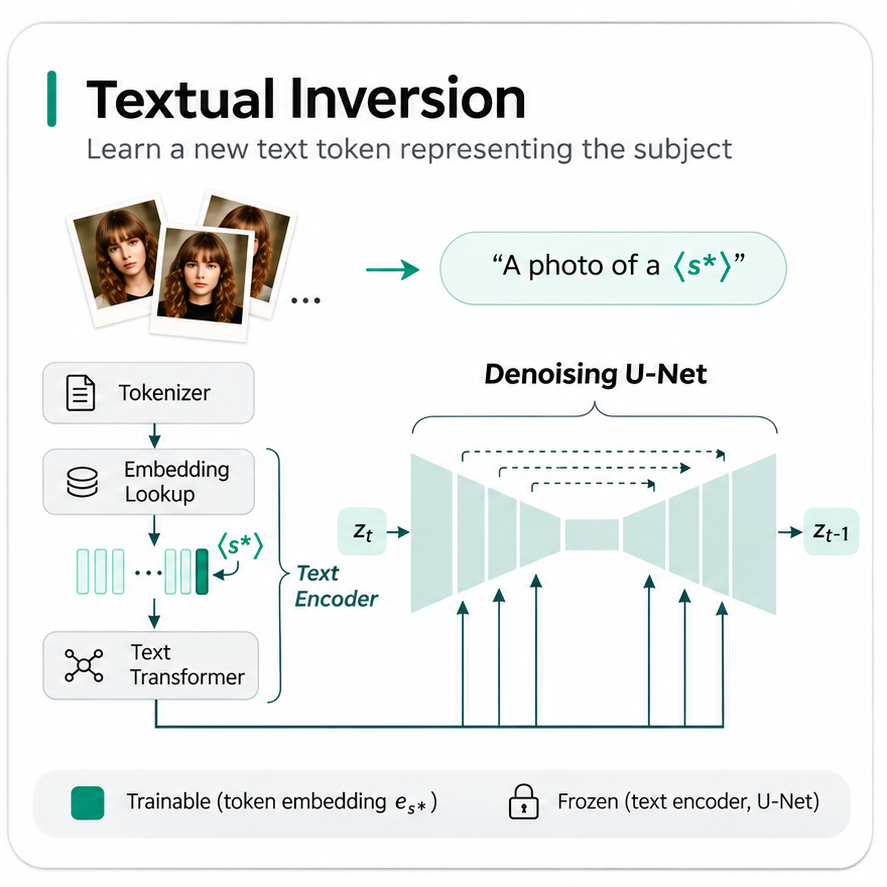<div style="font-size:13px;color:#6d6880;margin-top:8px">Textual Inversion: обучается только embedding нового токена.</div></div>


<div style="border-left:5px solid #9c7de5;background:#f4efff;padding:15px 18px;border-radius:0 12px 12px 0"><b>Идея.</b> Не меняем генератор. Добавляем один новый токен и обучаем только его вектор в CLIP text encoder. Это самая компактная форма персонализации.</div>

**Важно:** мы не fine-tune'им весь text encoder! У `nn.Embedding` технически один большой `Parameter`, но только **одна строка** действительно меняется; остальные восстанавливаются после каждого шага.

Чтобы очистить GPU перед следующим запуском, после сохранения уничтожаем компоненты модели.

In [ ]:
ti_cfg = CONFIGS["ti"]
tokenizer, text_encoder, vae, unet, scheduler = load_components()

NEW_TOKEN = "<cheburashka>"
assert tokenizer.add_tokens([NEW_TOKEN]) == 1, "Токен уже есть в словаре"
text_encoder.resize_token_embeddings(len(tokenizer))
new_id = tokenizer.convert_tokens_to_ids(NEW_TOKEN)
init_ids = tokenizer("toy", add_special_tokens=False).input_ids
assert len(init_ids) == 1, "Initializer word должен соответствовать одному токену"

with torch.no_grad():
    embeddings = text_encoder.get_input_embeddings().weight
    embeddings[new_id] = embeddings[init_ids[0]].clone()

text_encoder.requires_grad_(False)
text_encoder.get_input_embeddings().weight.requires_grad_(True)
vae.requires_grad_(False); unet.requires_grad_(False)
print("TI: физически обновляем только 1 embedding-вектор размерности", embeddings.shape[-1])

_, trained_ti, ti_history = train_one_method(
    ti_cfg, tokenizer, text_encoder, vae, unet, scheduler,
    trainable_parameters=[text_encoder.get_input_embeddings().weight],
    ti_token_id=new_id,
)

TI_DIR.mkdir(exist_ok=True)
vector = trained_ti.get_input_embeddings().weight[new_id].detach().float().cpu().contiguous()
save_file({NEW_TOKEN: vector}, str(TI_DIR / "learned_embeds.safetensors"))
show_loss(ti_history, "Textual Inversion — loss")
print("Сохранено:", TI_DIR / "learned_embeds.safetensors")
del trained_ti, tokenizer, text_encoder, vae, unet, scheduler
clear_gpu()

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

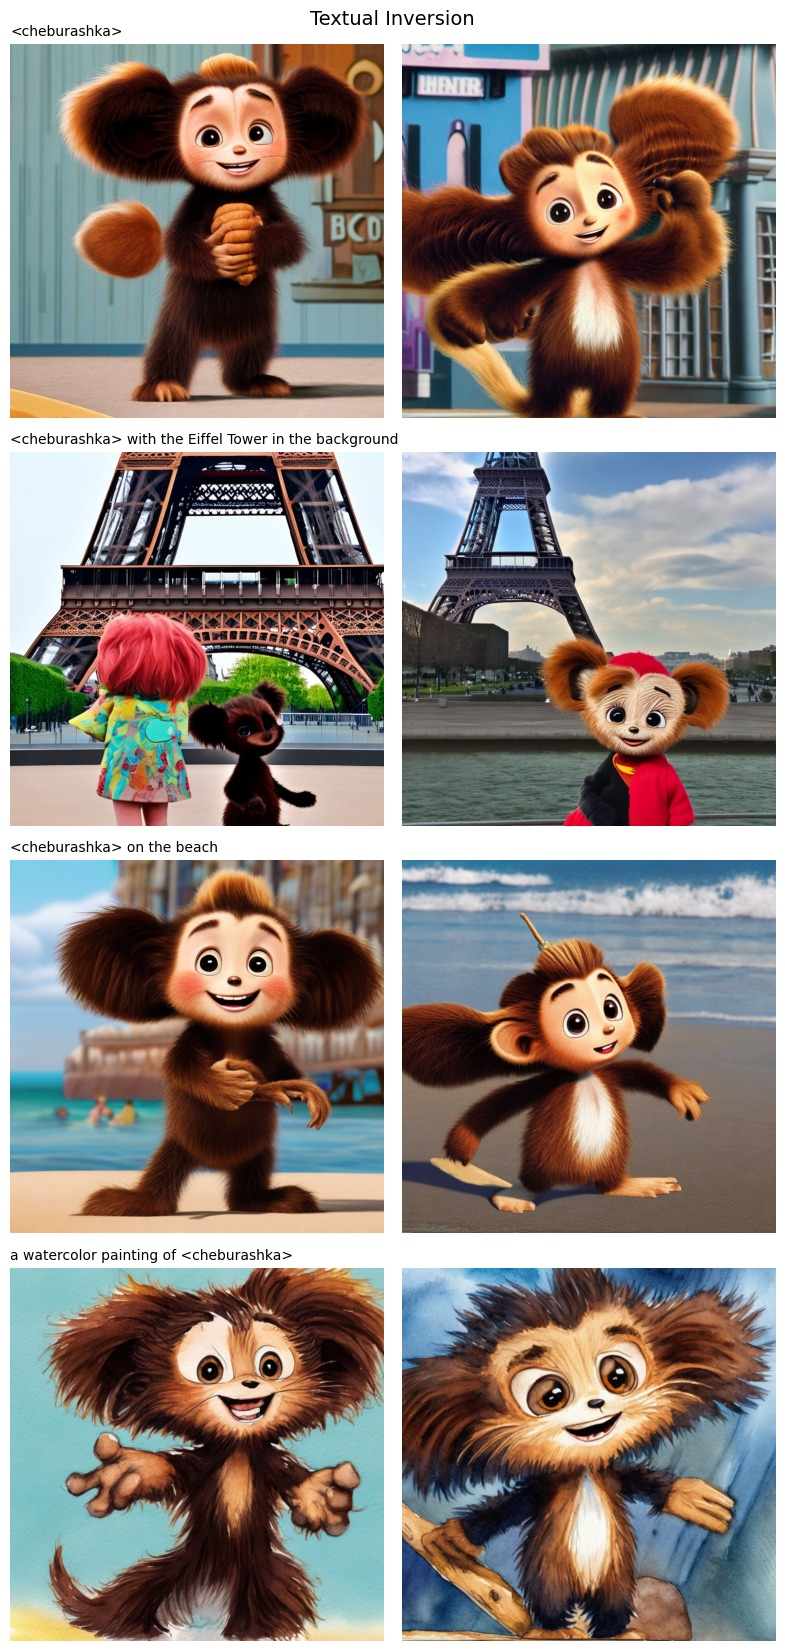

In [ ]:
show_method("ti", "Textual Inversion")

### Пока что полное зондбе
Учим очень мало параметров и еще и чисто текстовый эмбеддинг к которому диффузионная модель никак не приспособлена.
Отдельный интересный эксперимент - учить TI не на объект, а именно на стиль. Тогда не будет необходимости в точности передавать точные узнаваемые детали и модель выучит просто стилистический вайб.

## 04 · DreamBooth: U-Net + опциональный полный fine-tuning CLIP

📖 [**Статья · Ruiz et al., 2022 — DreamBooth: Fine Tuning Text-to-Image Diffusion Models for Subject-Driven Generation**](https://arxiv.org/abs/2208.12242)

<div style="margin:22px 0 18px;text-align:center">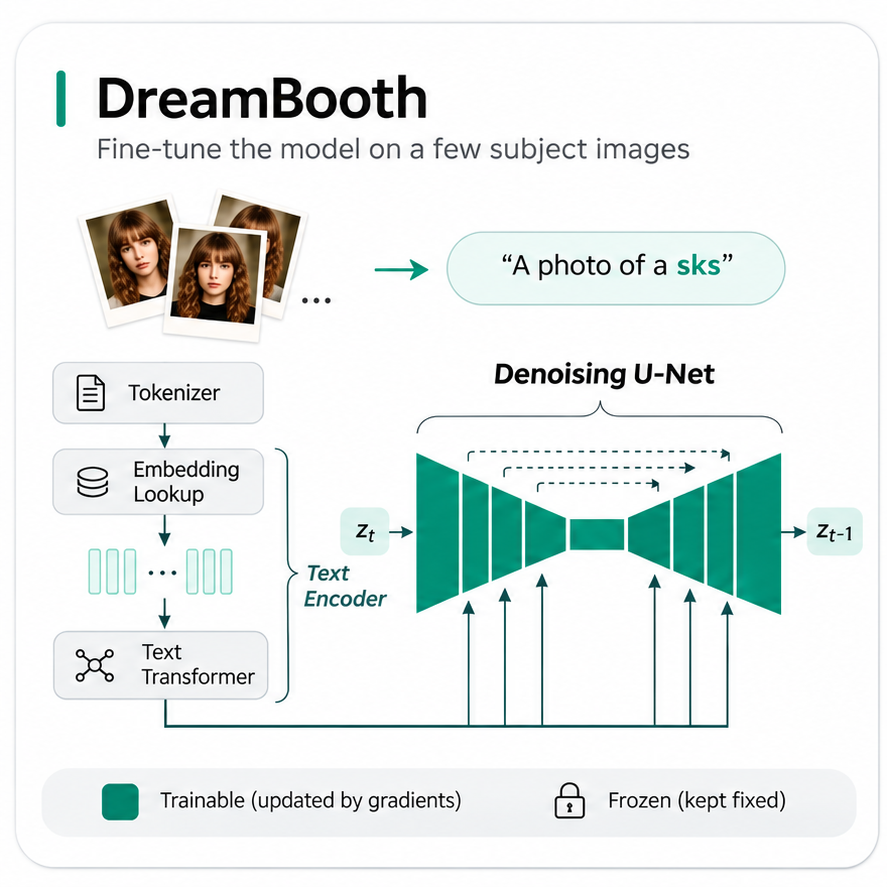<div style="font-size:13px;color:#6d6880;margin-top:8px">DreamBooth: обучение весов U-Net для персонализации.</div></div>


<div style="border-left:5px solid #9c7de5;background:#f4efff;padding:15px 18px;border-radius:0 12px 12px 0"><b>Идея.</b> Теперь обучаем <b>все веса U-Net</b>, тогда как CLIP text encoder и VAE заморожены. Учебная версия упрощена: без prior preservation и без обучения text encoder.</div>

DreamBooth гораздо более требователен к VRAM, чем TI и LoRA.

**Режим эксперимента:** `DREAMBOOTH_TRAIN_TEXT_ENCODER = True` включает оптимизацию всех параметров CLIP наряду с U-Net. При `False` CLIP остаётся заморожен. После обучения мы сохраняем обе компоненты, если CLIP обучался, и затем загружаем их вместе для генерации.


DreamBooth — U-Net:
Обучаемых параметров: 865,910,724 / 865,910,724 (100.0000%)
DreamBooth — CLIP:
Обучаемых параметров: 0 / 340,387,840 (0.0000%)


dreambooth:   0%|          | 0/101 [00:00<?, ?it/s]

Пик памяти GPU: 13.0 GiB


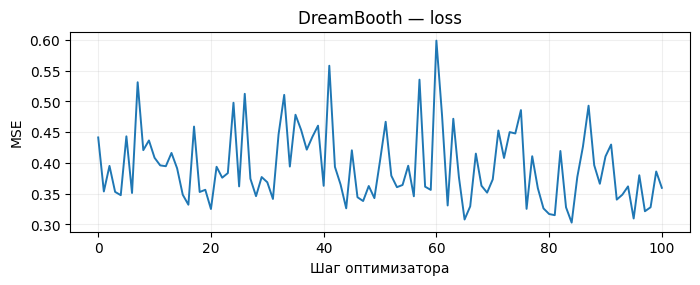

Сохранено: sd-personalization/dreambooth


Занято на GPU после очистки: 1.88 GiB


In [ ]:
db_cfg = CONFIGS["dreambooth"]
tokenizer, text_encoder, vae, unet, scheduler = load_components()
vae.requires_grad_(False)
unet.requires_grad_(True)
text_encoder.requires_grad_(DREAMBOOTH_TRAIN_TEXT_ENCODER)
unet.enable_gradient_checkpointing()  # Меньше VRAM ценой вычислений.
if DREAMBOOTH_TRAIN_TEXT_ENCODER:
    text_encoder.gradient_checkpointing_enable()

print("DreamBooth — U-Net:")
count_parameters(unet)
print("DreamBooth — CLIP:")
count_parameters(text_encoder)

# В оптимизатор идут обе группы параметров, только если они разморожены.
db_parameters = [p for model in (unet, text_encoder)
                 for p in model.parameters() if p.requires_grad]
trained_db_unet, trained_db_text, db_history = train_one_method(
    db_cfg, tokenizer, text_encoder, vae, unet, scheduler,
    trainable_parameters=db_parameters,
)
if not DREAMBOOTH_TRAIN_TEXT_ENCODER and (DB_DIR / "text_encoder").exists():
    import shutil
    shutil.rmtree(DB_DIR / "text_encoder")  # убираем CLIP из прошлого запуска
trained_db_unet.save_pretrained(DB_DIR / "unet", safe_serialization=True)
if DREAMBOOTH_TRAIN_TEXT_ENCODER:
    trained_db_text.save_pretrained(DB_DIR / "text_encoder", safe_serialization=True)
show_loss(db_history, "DreamBooth — loss")
print("Сохранено:", DB_DIR)
del trained_db_unet, trained_db_text, db_parameters, tokenizer, text_encoder, vae, unet, scheduler
clear_gpu()


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

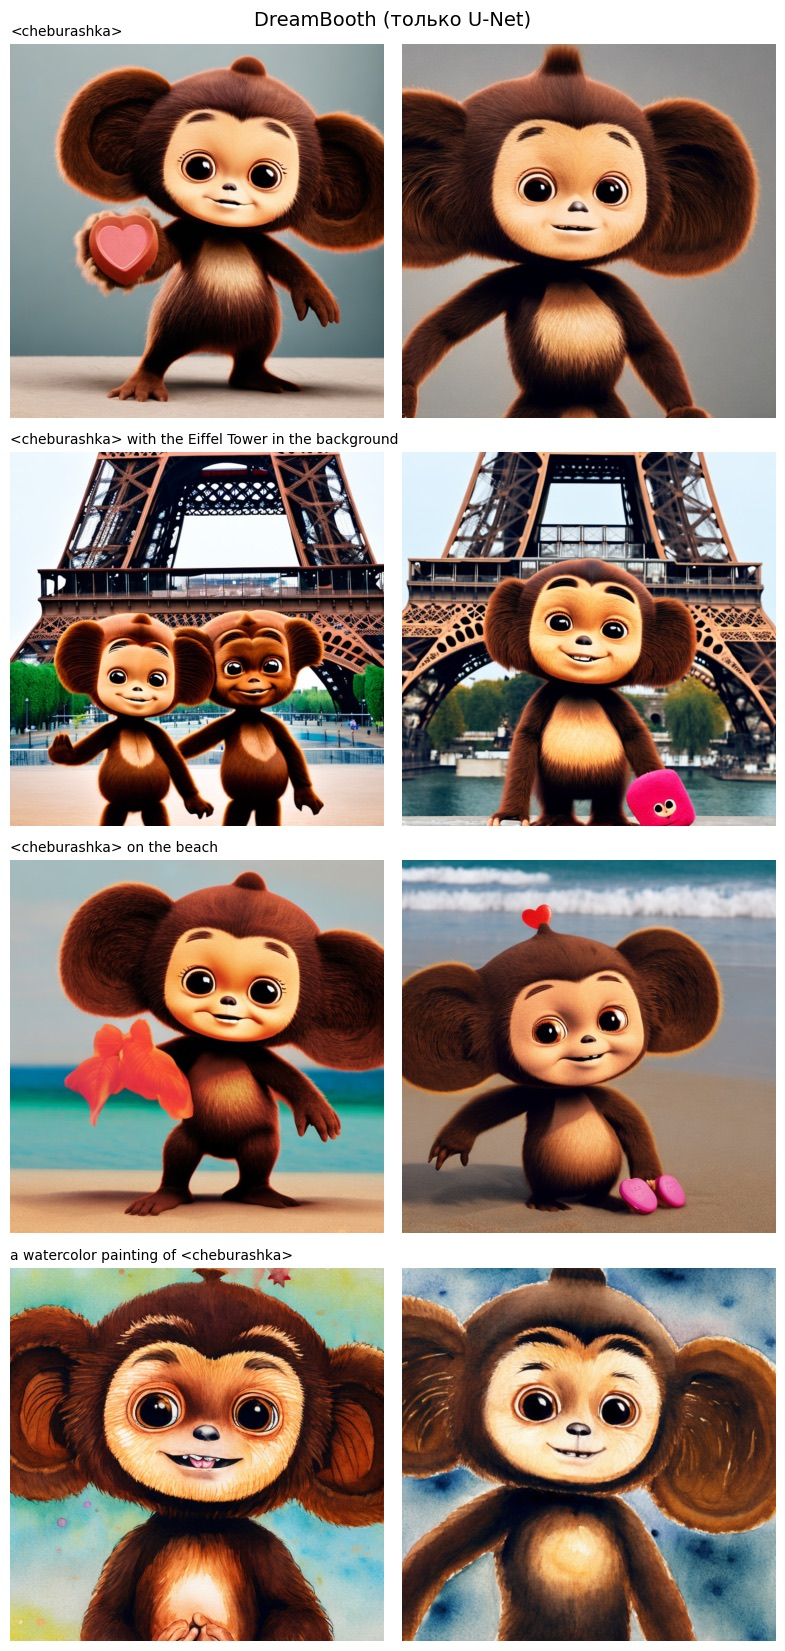

In [ ]:
show_method("dreambooth", "DreamBooth" + (" + CLIP" if DREAMBOOTH_TRAIN_TEXT_ENCODER else " (только U-Net)"))

### Как будто бы уже не такой страшненький, местами даже миленький, да?
Тут важно помнить что SD-2 сама по себе не очень крутая модель, которая очень часто и много генерирует артефакты, так что это вполне неплохой результат.

### 04.1 · Демонстрация: готовый DreamBooth + CLIP

Полное обучение U-Net вместе с CLIP на T4 занимает ~14.3 GiB — практически всю память карты, и любой остаток от предыдущих ячеек приводит к OOM. Вы можете попробовать запустить обучение предварительно почистив всю память, но на всякий случай я подготовила готовый чекпойнт. Он обучен заранее с теми же данными, prompt `<cheburashka> plushie` и гиперпараметрами (100 шагов, lr 5e-6, 768px), но с `train_text_encoder=True`.

Сравните с версией выше: сходство с оригиналом (брови, глаза, мех) заметно выше, но следите за тем, насколько хорошо модель следует промпту (фон, стиль).

Картинки в описании ноутбука тоже получены именно этим чекпойнтом. Тут уже чебурашка симпотичный даже.

checkpoint-100/unet.bin:   0%|          | 0.00/3.46G [00:00<?, ?B/s]

checkpoint-100/te.bin:   0%|          | 0.00/1.36G [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

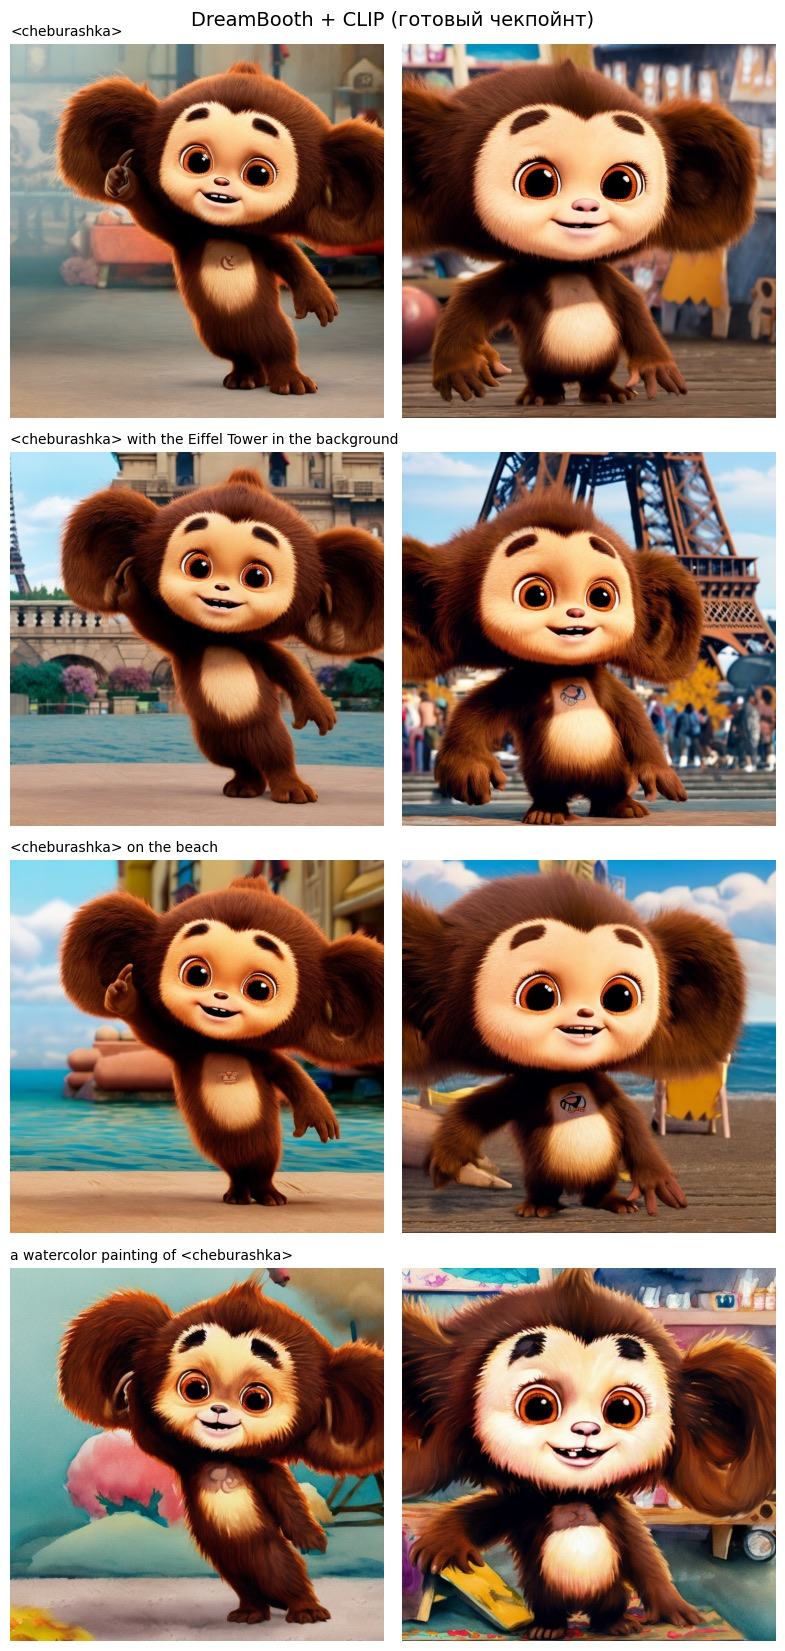

In [ ]:
for filename in ("checkpoint-100/unet.bin", "checkpoint-100/te.bin"):
    hf_hub_download(repo_id="verasobol/cheburashka-db-te", filename=filename, local_dir=DB_TE_DIR)

show_method("dreambooth_te", "DreamBooth + CLIP (готовый чекпойнт)")

## 05 · LoRA rank 4 через PEFT

📖 [**Статья · Hu et al., 2021 — LoRA: Low-Rank Adaptation of Large Language Models**](https://arxiv.org/abs/2106.09685)

<div style="margin:22px 0 18px;text-align:center">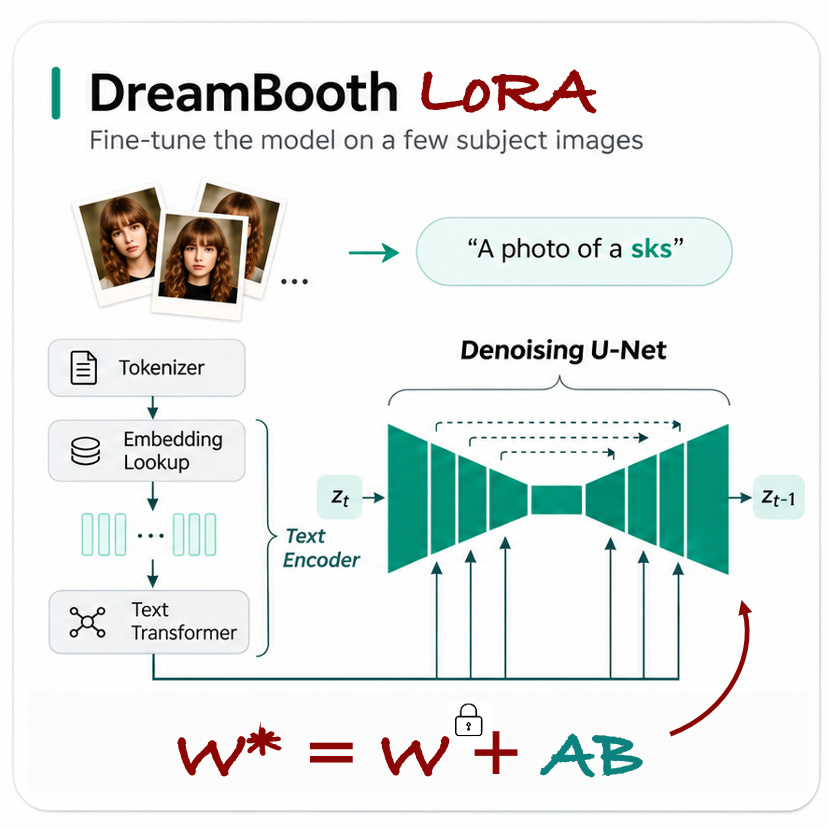<div style="font-size:13px;color:#6d6880;margin-top:8px">LoRA: низкоранговое обновление весов вместо полного fine-tuning.</div></div>


<div style="border-left:5px solid #9c7de5;background:#f4efff;padding:15px 18px;border-radius:0 12px 12px 0"><b>Идея.</b> К исходной линейной проекции добавляем низкоранговую поправку: <code>W' = W + (α/r)BA</code>, где <code>A ∈ R^{r×d_in}</code>, <code>B ∈ R^{d_out×r}</code>. Обучаем только A и B, исходная W заморожена.</div>

Для `r=4` адаптируем attention-проекции U-Net: `to_q`, `to_k`, `to_v`, `to_out.0`. Параметры PEFT создаёт автоматически.

**Сравните** количество обучаемых параметров с DreamBooth выше.

**LoRA + CLIP:** при `LORA_TRAIN_TEXT_ENCODER = True` обучаем два набора LoRA-матриц — в attention-проекциях U-Net и CLIP (`q_proj`, `k_proj`, `v_proj`, `out_proj`). Сами предобученные веса CLIP остаются замороженными. Веса обеих LoRA сохраняются в **одном Diffusers-чекпойнте** и загружаются одним `load_lora_weights`.


LoRA — U-Net:
Обучаемых параметров: 829,952 / 866,740,676 (0.0958%)
LoRA — CLIP:
Обучаемых параметров: 0 / 340,387,840 (0.0000%)


lora:   0%|          | 0/400 [00:00<?, ?it/s]

Пик памяти GPU: 9.1 GiB


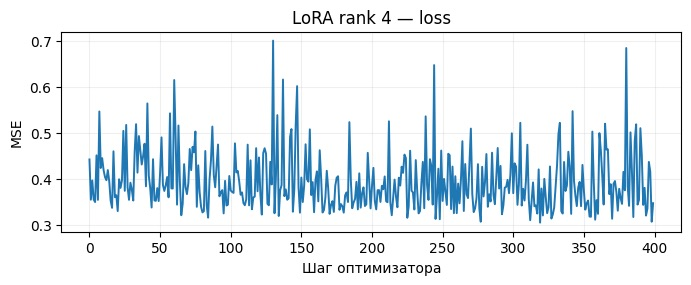

Сохранено: sd-personalization/lora


Занято на GPU после очистки: 1.88 GiB


In [ ]:
lora_cfg = CONFIGS["lora"]
tokenizer, text_encoder, vae, unet, scheduler = load_components()
vae.requires_grad_(False)
text_encoder.requires_grad_(False)
unet.requires_grad_(False)

# add_adapter встраивает PEFT-LoRA прямо в модель diffusers, имена слоёв не меняются.
unet.add_adapter(LoraConfig(
    r=LORA_RANK, lora_alpha=LORA_RANK, lora_dropout=0.0,
    init_lora_weights="gaussian",
    target_modules=["to_q", "to_k", "to_v", "to_out.0"],
))
unet.enable_gradient_checkpointing()

if LORA_TRAIN_TEXT_ENCODER:
    text_encoder.add_adapter(LoraConfig(
        r=LORA_RANK, lora_alpha=LORA_RANK, lora_dropout=0.0,
        init_lora_weights="gaussian",
        target_modules=["q_proj", "k_proj", "v_proj", "out_proj"],
    ))

print("LoRA — U-Net:")
count_parameters(unet)
print("LoRA — CLIP:")
count_parameters(text_encoder)

lora_parameters = [p for model in (unet, text_encoder)
                   for p in model.parameters() if p.requires_grad]
trained_lora_unet, trained_lora_text, lora_history = train_one_method(
    lora_cfg, tokenizer, text_encoder, vae, unet, scheduler,
    trainable_parameters=lora_parameters,
)

# Один чекпойнт для LoRA U-Net и (опционально) LoRA CLIP.
unet_state = convert_state_dict_to_diffusers(
    get_peft_model_state_dict(trained_lora_unet)
)
text_state = None
if LORA_TRAIN_TEXT_ENCODER:
    text_state = convert_state_dict_to_diffusers(
        get_peft_model_state_dict(trained_lora_text)
    )
StableDiffusionPipeline.save_lora_weights(
    save_directory=str(LORA_DIR),
    unet_lora_layers=unet_state,
    text_encoder_lora_layers=text_state,
    safe_serialization=True,
)
show_loss(lora_history, f"LoRA rank {LORA_RANK} — loss")
print("Сохранено:", LORA_DIR)
del trained_lora_unet, trained_lora_text, lora_parameters, tokenizer, text_encoder
del vae, unet, scheduler, unet_state, text_state
clear_gpu()


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


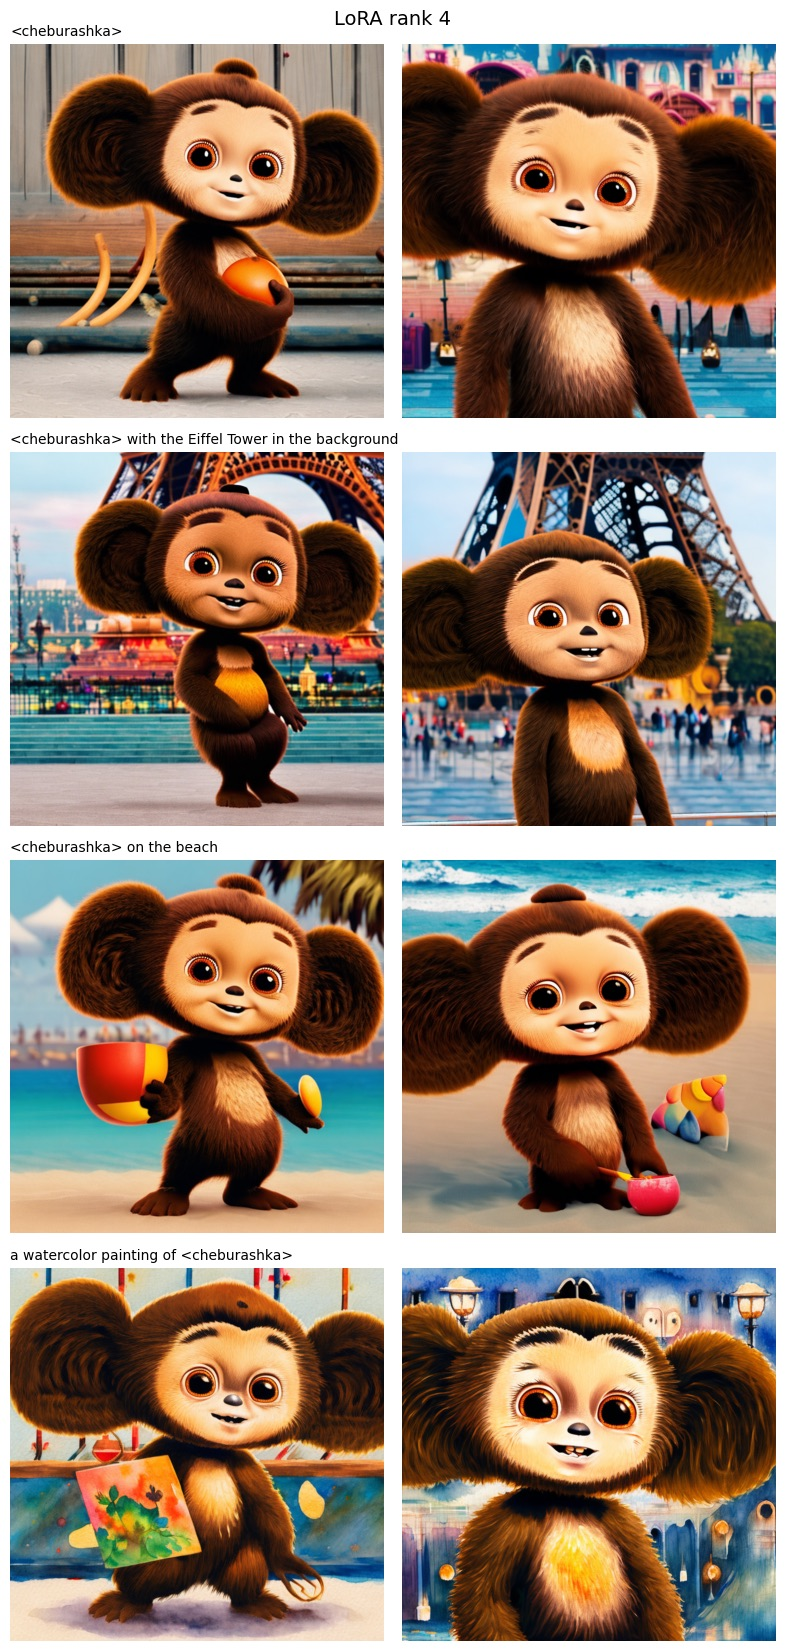

In [ ]:
show_method("lora", f"LoRA rank {LORA_RANK}")

### Сравните баланс гибкости генерации с уровнем симпотичности чебурашки.
На мой взгляд он тут выше всех. И соответствие промпту хорошее и чебурашка узнается и не кринжовый.

Поразмышляйте о том, как связаны качество, гибкость генерации и число обучаемых параметров. А также то, где именно мы их учим. А что будет если в текстовом энкодере учить эмбеддинг как в TI и одновременно на юнет накинуть лору? Попробуйте, если хотите.

## 06 · Эксперимент: LoRA своими руками (домашнее задание)

PEFT скрывает механику замены слоёв. Ниже мы самостоятельно создаём `nn.Linear`-обёртку с двумя обучаемыми матрицами и **заменяем** выбранные `nn.Linear` внутри U-Net. Эта часть **не запускает обучение** и не реализует save/load — это оставлено как домашнее задание.

Почему `B` инициализируется нулями? Чтобы новая модель **в точности совпадала** с исходной до первого шага оптимизации.

Задание: (1) повторить общий обучающий цикл для этих модулей, (2) сохранить только `A`, `B`, (3) загрузить их в новую U-Net, (4) сравнить выходы с PEFT при одинаковой инициализации.

In [ ]:
import torch.nn as nn

class ExplicitLoRALinear(nn.Module):
    """W' x = W x + (alpha / r) B(Ax), без модификации исходного W."""
    def __init__(self, base_layer: nn.Linear, rank=8, alpha=8):
        super().__init__()
        if not isinstance(base_layer, nn.Linear):
            raise TypeError("Ожидается nn.Linear")
        self.base_layer = base_layer
        self.base_layer.requires_grad_(False)
        self.rank = rank
        self.scale = alpha / rank
        self.lora_A = nn.Linear(base_layer.in_features, rank, bias=False)
        self.lora_B = nn.Linear(rank, base_layer.out_features, bias=False)
        # Не меняем initial output: B = 0.
        nn.init.normal_(self.lora_A.weight, std=1 / rank)
        nn.init.zeros_(self.lora_B.weight)
        # Если base уже на GPU / fp16, держим новые веса в той же среде.
        self.lora_A.to(device=base_layer.weight.device, dtype=base_layer.weight.dtype)
        self.lora_B.to(device=base_layer.weight.device, dtype=base_layer.weight.dtype)

    def forward(self, x):
        return self.base_layer(x) + self.scale * self.lora_B(self.lora_A(x))


def inject_explicit_lora(module, target_names=("to_q", "to_k", "to_v", "to_out.0"),
                         rank=8, alpha=8):
    """Рекурсивно заменяем только выбранные линейные проекции U-Net."""
    replacements = []
    for full_name, child in list(module.named_modules()):
        if not isinstance(child, nn.Linear):
            continue
        if not any(full_name.endswith(t) for t in target_names):
            continue
        parent_name, _, leaf_name = full_name.rpartition(".")
        parent = module.get_submodule(parent_name) if parent_name else module
        setattr(parent, leaf_name, ExplicitLoRALinear(child, rank=rank, alpha=alpha))
        replacements.append(full_name)
    return replacements

# Маленький smoke test без загрузки Stable Diffusion:
example = nn.Linear(16, 12)
wrapped = ExplicitLoRALinear(example, rank=8)
x = torch.randn(2, 16)
assert torch.allclose(wrapped(x), example(x), atol=1e-6)
assert all(not p.requires_grad for p in wrapped.base_layer.parameters())
print("✅ ExplicitLoRALinear совпадает с исходным слоем до обучения")

# ДЕМОНСТРАЦИЯ вызова (не выполняем, чтобы не загружать U-Net повторно):
# unet = UNet2DConditionModel.from_pretrained(MODEL_ID, subfolder="unet")
# unet.requires_grad_(False)
# names = inject_explicit_lora(unet, rank=8, alpha=8)
# print("Заменено слоёв:", len(names))
# optimizer = torch.optim.AdamW((p for p in unet.parameters() if p.requires_grad), lr=1e-4)

✅ ExplicitLoRALinear совпадает с исходным слоем до обучения


## 07 · Сравнение генераций: один prompt, один seed

Дальше мы загружаем **по одному** обученному варианту и смотрим результат. На T4 это экономит память; не держите одновременно несколько полных pipeline.

Все методы используют токен `<cheburashka>`, базовая модель — обычное слово `cheburashka`. Сид и настройки генерации одинаковые, поэтому разница между картинками — только заслуга метода. `dreambooth_te` — готовый чекпойнт DreamBooth + CLIP из раздела 04.

In [ ]:
# Убирайте из списка методы, которые не обучали в этой сессии.
METHODS_TO_COMPARE = ["base", "ti", "dreambooth", "lora", "dreambooth_te"]


def compare_methods(template, methods=METHODS_TO_COMPARE, seed=GEN_SEED):
    """Один prompt и один сид для всех методов; pipeline загружаем по одной."""
    fig, axes = plt.subplots(1, len(methods), figsize=(4 * len(methods), 4.6))
    for ax, method in zip(np.atleast_1d(axes), methods):
        pipe = load_pipe(method)
        image = generate(pipe, template.format(method_token(method)), seed=seed, num_images=1)[0]
        ax.imshow(image); ax.set_title(method); ax.axis("off")
        del pipe
        clear_gpu(verbose=False)
    fig.suptitle(template.format("<cheburashka>"))
    plt.tight_layout(); plt.show()

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

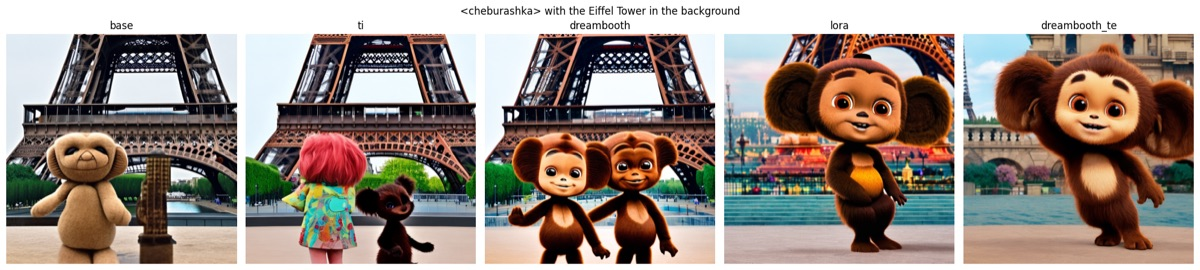

In [ ]:
compare_methods("{} with the Eiffel Tower in the background")

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

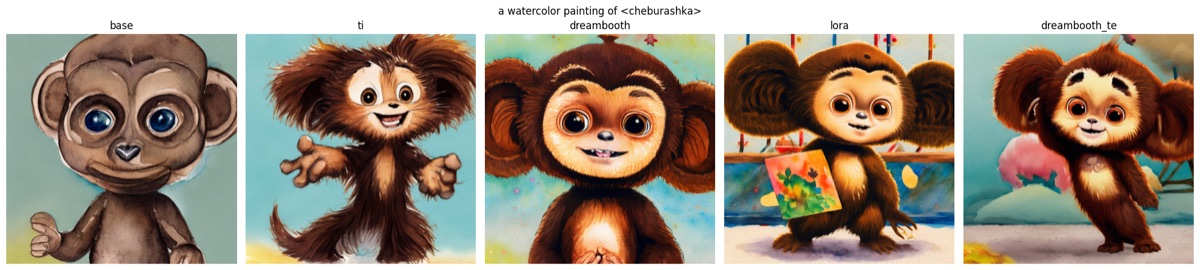

In [ ]:
# Перенос стиля: какой метод сильнее «залипает» на фотореализм обучающих картинок?
compare_methods("a watercolor painting of {}")

## Вопросы к разделам 04-07

1) Лосс не падает, выглядит хаотично и рандомно, но при этом мы видимо, что объект выучивается. Почему такая картина лосса?(присмотритесь к тому что приходит на вход модели каждую итерацию)

2) Попробуйте разные промпты для пункта 07. Разные стили/сцены/аксессуары/позы объекта. Какой метод лучше всего генерирует объект, а какой сильнее всего переобучается и хуже всего следует промпту? Какие артефакты переобучения особенно заметны?

3) Сравните DreamBooth без текстового энкодера и готовый DreamBooth + CLIP из 04.1. Затем обучите LoRA с `LORA_TRAIN_TEXT_ENCODER = True`. Как меняется сходство и следование промпту?



## 08 · IP-Adapter: управление по референсу

📖 [**Статья · Ye et al., 2023 — IP-Adapter: Text Compatible Image Prompt Adapter for Text-to-Image Diffusion Models**](https://arxiv.org/abs/2308.06721)

До сих пор мы **обучали** новые параметры. IP-Adapter — другой режим: готовый image-conditioning адаптер принимает *референсное изображение* и помогает перенести его визуальное содержание в генерацию. **Здесь ничего не обучаем.**

Оставим ту же SD 1.5, возьмём первое изображение игрушки и сравним два значения `set_ip_adapter_scale`. Считаем это отдельным inference-экспериментом; результат не эквивалентен обучению новой идентичности.

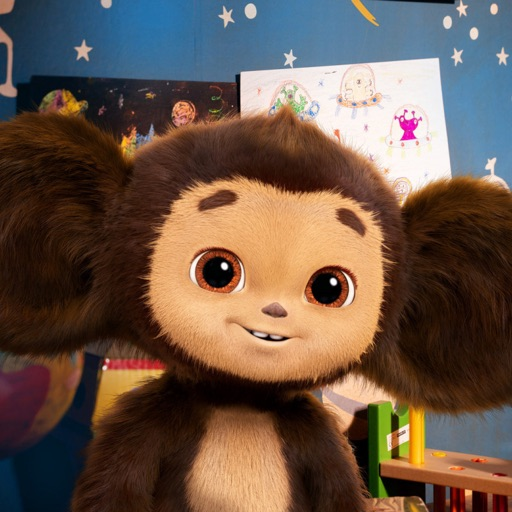

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

`torch_dtype` is deprecated! Use `dtype` instead!


  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

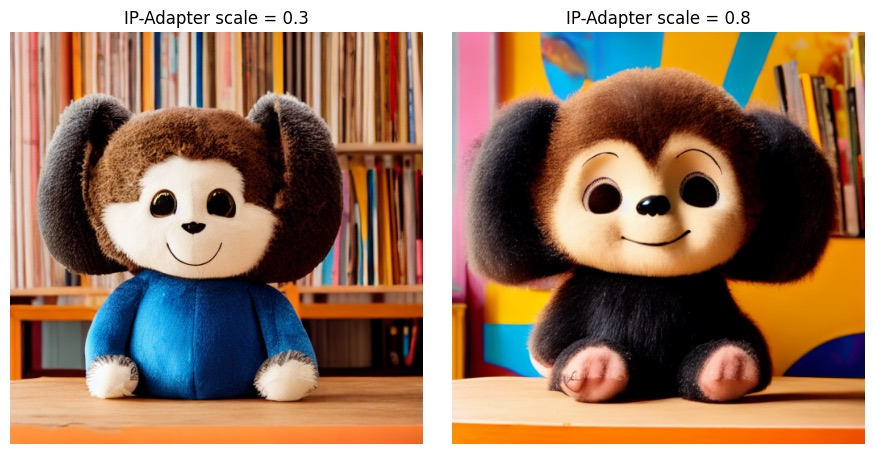

Занято на GPU после очистки: 1.88 GiB


In [ ]:
reference_image = Image.open(image_paths[0]).convert("RGB")
reference_image = ImageOps.fit(reference_image, (512, 512))
display(reference_image)

pipe = StableDiffusionPipeline.from_pretrained(
    SD15_MODEL_ID, torch_dtype=torch.float16, safety_checker=None,
    requires_safety_checker=False,
).to(DEVICE)
pipe.load_ip_adapter("h94/IP-Adapter", subfolder="models", weight_name="ip-adapter_sd15.bin")

ip_images = []
for scale in (0.3, 0.8):
    pipe.set_ip_adapter_scale(scale)
    with torch.inference_mode():
        img = pipe(
            prompt="a plush toy on a wooden table, editorial studio photography",
            ip_adapter_image=reference_image,
            num_inference_steps=25,
            generator=torch.Generator("cpu").manual_seed(GEN_SEED),
        ).images[0]
    ip_images.append(img)

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
for ax, img, scale in zip(axes, ip_images, (0.3, 0.8)):
    ax.imshow(img); ax.set_title(f"IP-Adapter scale = {scale}"); ax.axis("off")
plt.tight_layout(); plt.show()
del pipe
clear_gpu()

Можете попробовать подгрузить свою фотку и поиграться. Изучите как меняется объект и фон при изменении scale.

## 09 · ControlNet Canny + стилевая LoRA

📖 [**Статья · Zhang et al., 2023 — Adding Conditional Control to Text-to-Image Diffusion Models**](https://arxiv.org/abs/2302.05543)

**ControlNet** отвечает за *геометрию*: края и контуры из Canny-карты. **LoRA** — за *стиль*, поэтому их можно сочетать.

Пайплайн получает два независимых сигнала:

**Prompt + LoRA (что и в каком стиле изображать)** → U-Net ← **Canny + ControlNet (как расположить)**

Берём фотографию девушки из датасета [Ronii112233/Women_01](https://huggingface.co/datasets/Ronii112233/Women_01), строим по ней Canny-карту и генерируем «блондинку на дождливой улице» в четырёх вариантах: без всего, только с ControlNet, только с LoRA, с LoRA и ControlNet. Модель — SD 1.5, ControlNet — [`lllyasviel/control_v11p_sd15_canny`](https://huggingface.co/lllyasviel/control_v11p_sd15_canny), LoRA — готовая стилевая [`neonforestmist/sd15-storybook-anime-lora`](https://huggingface.co/neonforestmist/sd15-storybook-anime-lora) (триггер `storybook anime illustration`). Промпт и seed во всех вариантах одинаковые, меняются только подключённые адаптеры. **Ничего не обучаем.**


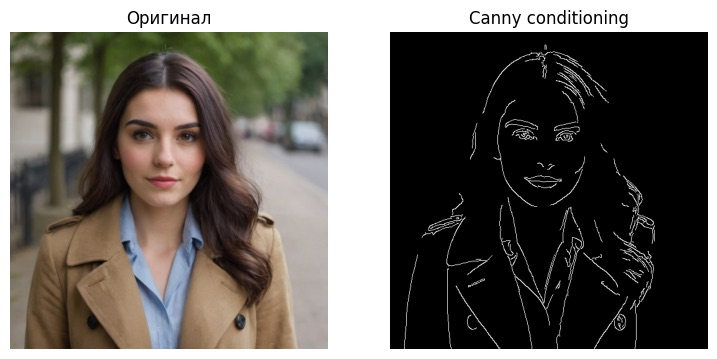

In [ ]:
import cv2
import io
import pyarrow.parquet as pq

# Третья картинка датасета (женщина в плаще на улице).
women_parquet = hf_hub_download(
    "Ronii112233/Women_01", "default/train/0000.parquet",
    repo_type="dataset", revision="refs/convert/parquet",
)
row = pq.read_table(women_parquet).slice(2, 1).column("image").to_pylist()[0]
control_reference = Image.open(io.BytesIO(row["bytes"])).convert("RGB").resize((512, 512))

edges = cv2.Canny(np.asarray(control_reference), threshold1=100, threshold2=200)
canny_image = Image.fromarray(np.repeat(edges[..., None], 3, axis=2))
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
axes[0].imshow(control_reference); axes[0].set_title("Оригинал")
axes[1].imshow(canny_image); axes[1].set_title("Canny conditioning")
for ax in axes: ax.axis("off")
plt.show()


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

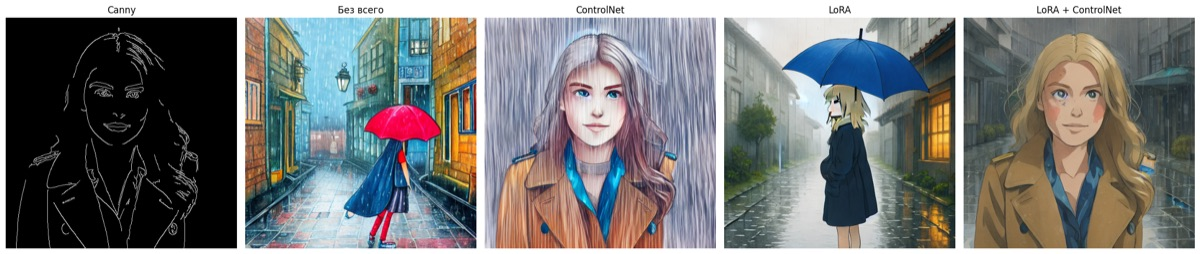

Занято на GPU после очистки: 3.93 GiB


In [ ]:
controlnet = ControlNetModel.from_pretrained("lllyasviel/control_v11p_sd15_canny", torch_dtype=torch.float16)
cn_pipe = StableDiffusionControlNetPipeline.from_pretrained(
    SD15_MODEL_ID, controlnet=controlnet, torch_dtype=torch.float16,
    safety_checker=None, requires_safety_checker=False,
).to(DEVICE)
# Тот же U-Net, VAE и text encoder, но без ControlNet: веса не копируются.
sd_pipe = StableDiffusionPipeline(
    **{k: v for k, v in cn_pipe.components.items() if k != "controlnet"}, requires_safety_checker=False
)
for p in (cn_pipe, sd_pipe):
    p.set_progress_bar_config(disable=True)

# LoRA встраивается в общий U-Net, поэтому действует в обоих пайплайнах.
cn_pipe.load_lora_weights(
    "neonforestmist/sd15-storybook-anime-lora",
    weight_name="storybook_anime_lora.safetensors", adapter_name="storybook",
)

prompt = (
    "storybook anime illustration, a blonde girl on a rainy street, wet pavement, umbrellas, "
    "warm hand-painted background, soft cel-shaded characters, whimsical children's book anime style"
)
negative_prompt = "lowres, blurry, deformed, bad anatomy, extra fingers, text, watermark"

def generate_cn(use_lora, use_controlnet, lora_scale=0.85, control_scale=1.0):
    if use_lora:
        cn_pipe.enable_lora()
        cn_pipe.set_adapters(["storybook"], adapter_weights=[lora_scale])
    else:
        cn_pipe.disable_lora()
    kwargs = dict(
        prompt=prompt, negative_prompt=negative_prompt,
        num_inference_steps=GEN_STEPS, guidance_scale=7.5,
        generator=torch.Generator("cpu").manual_seed(GEN_SEED),
    )
    with torch.inference_mode():
        if use_controlnet:
            return cn_pipe(image=canny_image, controlnet_conditioning_scale=control_scale, **kwargs).images[0]
        return sd_pipe(height=512, width=512, **kwargs).images[0]

panels = [
    ("Без всего", generate_cn(False, False)),
    ("ControlNet", generate_cn(False, True)),
    ("LoRA", generate_cn(True, False)),
    ("LoRA + ControlNet", generate_cn(True, True)),
]
fig, axes = plt.subplots(1, 5, figsize=(22, 4.8))
for ax, (title, img) in zip(axes, [("Canny", canny_image)] + panels):
    ax.imshow(img); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()
del cn_pipe, sd_pipe, controlnet
clear_gpu()


## 10 · Практика (основное домашнее задание)

- Заменить выбранные attention-слои U-Net на `ExplicitLoRALinear` при `rank=4`.
- С использованием общего цикла обучения оптимизировать **только** `lora_A` и `lora_B`.
- Сохранить их компактный state dict и загрузить в новую исходную модель.
- Проверить численное равенство output до обучения, а после — сравнить явную LoRA и PEFT на одинаковом prompt/seed.

**Дополнительное исследование:** обучить LoRA на другом rank и исследовать взаимосвязь числа параметров, размера чекпойнта и качества.

---

### Полезные материалы
- [Diffusers: Textual Inversion](https://huggingface.co/docs/diffusers/training/text_inversion)
- [Diffusers: DreamBooth](https://huggingface.co/docs/diffusers/training/dreambooth)
- [Diffusers: LoRA](https://huggingface.co/docs/diffusers/training/lora)
- [Diffusers: IP-Adapter](https://huggingface.co/docs/diffusers/using-diffusers/ip_adapter)
- [Diffusers: ControlNet](https://huggingface.co/docs/diffusers/using-diffusers/controlnet)
